In [3]:
# ============================================================
# REPLICATION: Rodrik (2008) — Table 1
# "The Real Exchange Rate and Economic Growth"
#
# Goal: Replicate Table 1 of Rodrik (2008) in order to learn the
# exact methodology used in this highly influential academic
# publication. The replication is not an end in itself: once the
# procedure is fully understood and reproduced, the same
# methodology will be applied to a more recent dataset to
# analyze, with up-to-date empirical evidence, the relationship
# between the real exchange rate and economic growth.
#
# Methodology replicated here:
#   1. Clean Penn World Table 6.2 data
#   2. Build five-year averages of the real exchange rate (RER)
#      and real GDP per capita
#   3. Estimate the Balassa-Samuelson effect and derive an
#      undervaluation index (the residual)
#   4. Run the six growth regressions of Table 1 (country and
#      period fixed effects, robust standard errors)
#   5. Format the results as a publication-style table
# ============================================================

# ------------------------------------------------------------
# 1. LIBRARIES
# ------------------------------------------------------------

import pandas as pd                      # data manipulation
import numpy as np                       # numerical operations
import matplotlib.pyplot as plt          # plotting (Figure 2)
import statsmodels.formula.api as smf    # regressions with R-style formulas

# ------------------------------------------------------------
# 2. LOAD AND EXPLORE DATA
# ------------------------------------------------------------

# Load the Penn World Table 6.2 data (data is on the second sheet)
pwt62_raw = pd.read_excel(
    "pwt62_data.xlsx",
    sheet_name=1
)

# Preview the raw data (first 25 rows) to inspect its structure
# and variables before any transformation
print(pwt62_raw.head(25))

        country country isocode  year        POP       XRAT        PPP  \
0   Afghanistan             AFG  1950   8150.368         na         na   
1   Afghanistan             AFG  1951   8284.473         na         na   
2   Afghanistan             AFG  1952   8425.333         na         na   
3   Afghanistan             AFG  1953   8573.217         na         na   
4   Afghanistan             AFG  1954   8728.408         na         na   
5   Afghanistan             AFG  1955   8891.209       16.8         na   
6   Afghanistan             AFG  1956   9061.938         20         na   
7   Afghanistan             AFG  1957   9240.934         20         na   
8   Afghanistan             AFG  1958   9428.556         20         na   
9   Afghanistan             AFG  1959   9624.606         20         na   
10  Afghanistan             AFG  1960    9829.45         20         na   
11  Afghanistan             AFG  1961  10043.473         20         na   
12  Afghanistan             AFG  1962 

In [4]:
# ------------------------------------------------------------
# 3. CLEAN DATA
# ------------------------------------------------------------

# Keep only the variables needed:
#   p      = price level of GDP (PPP / exchange rate, in percent)
#   rgdpch = real GDP per capita (chain index)
pwt62 = pwt62_raw[
    ["country", "year", "p", "rgdpch"]
].copy()

# The raw file encodes missing values as the string "na";
# convert them to proper NaN values
pwt62["p"] = pwt62["p"].replace("na", np.nan)
pwt62["rgdpch"] = pwt62["rgdpch"].replace("na", np.nan)

# Force numeric types (anything unparseable becomes NaN)
pwt62["p"] = pd.to_numeric(
    pwt62["p"],
    errors="coerce"
)

pwt62["rgdpch"] = pd.to_numeric(
    pwt62["rgdpch"],
    errors="coerce"
)

# Use a nullable integer type for year so missing values are tolerated
pwt62["year"] = pd.to_numeric(
    pwt62["year"],
    errors="coerce"
).astype("Int64")

# ------------------------------------------------------------
# 4. CREATE period
# ------------------------------------------------------------

# Assign each year to a five-year window identified by its
# starting year (e.g. 1950-1954 -> 1950, 1955-1959 -> 1955)
pwt62["period"] = (
    np.floor(pwt62["year"].astype(float) / 5) * 5
).astype("int64")

# ------------------------------------------------------------
# 5. CREATE p.
# ------------------------------------------------------------

# Convert the PWT price level into a real exchange rate (RER):
# since p = PPP/XR * 100, the RER (XR/PPP) is 100 / p.
# Higher values mean a more depreciated (undervalued) currency.
pwt62["p."] = 100 / pwt62["p"]

# ------------------------------------------------------------
# 6. FIVE-YEAR AVERAGES
# ------------------------------------------------------------

# Group observations by country and five-year period
grouped = pwt62.groupby(
    ["country", "period"]
)

# Number of non-missing observations in each group
# (used to avoid computing averages over empty groups)
n_p = grouped["p."].transform("count")
n_rgdpch = grouped["rgdpch"].transform("count")

# Five-year group means, broadcast back to every row of the group
mean_p = grouped["p."].transform("mean")
mean_rgdpch = grouped["rgdpch"].transform("mean")

# Log of the five-year average RER (NaN if the group has no data)
pwt62["lnRER_it"] = np.where(
    n_p > 0,
    np.log(mean_p),
    np.nan
)

# Log of the five-year average real GDP per capita
pwt62["lnRGDPCH_it"] = np.where(
    n_rgdpch > 0,
    np.log(mean_rgdpch),
    np.nan
)

# ------------------------------------------------------------
# 7. CREATE INITIAL INCOME
# ------------------------------------------------------------

# Build a lookup table: (country, period) -> log GDP per capita.
# One row per country-period is kept, since the averages are
# identical for every year within the same group.
income_lookup = (
    pwt62[
        ["country", "period", "lnRGDPCH_it"]
    ]
    .drop_duplicates(
        ["country", "period"]
    )
    .set_index(
        ["country", "period"]
    )["lnRGDPCH_it"]
)

# For each row, build the key of the PREVIOUS five-year period
previous_period = pd.MultiIndex.from_arrays(
    [
        pwt62["country"],
        pwt62["period"] - 5
    ],
    names=["country", "period"]
)

# Initial income = log GDP per capita of the previous period
# (NaN when the country has no previous period in the data)
pwt62["lnRGDPCH_it_1"] = (
    income_lookup
    .reindex(previous_period)
    .to_numpy()
)

# ------------------------------------------------------------
# 8. CREATE ECONOMIC GROWTH
# ------------------------------------------------------------

# Annualized growth rate between consecutive five-year periods:
# exp((ln Y_t - ln Y_{t-1}) / 5) - 1
pwt62["growth_it"] = (
    np.exp(
        (
            pwt62["lnRGDPCH_it"]
            - pwt62["lnRGDPCH_it_1"]
        ) / 5
    )
    - 1
)

# ------------------------------------------------------------
# 9. DEVELOPED / DEVELOPING CLASSIFICATION
# ------------------------------------------------------------

# Rodrik's rule: a country-period is "developed" if its real
# GDP per capita exceeds $6,000 (1 = developed, 0 = developing)
pwt62["developed"] = np.where(
    np.exp(pwt62["lnRGDPCH_it"]) > 6000,
    1,
    0
)

# ------------------------------------------------------------
# 10. COLLAPSE TO FIVE-YEAR OBSERVATIONS
# ------------------------------------------------------------

# Collapse the annual panel to one row per country-period.
# All constructed variables are constant within a group, so
# taking the first row is enough.
pwt62 = (
    pwt62
    .groupby(
        ["country", "period"],
        sort=False,
        as_index=False
    )
    .first()
)

# Drop country-periods with no RER or no income data
pwt62 = pwt62[
    pwt62["lnRER_it"].notna()
    & pwt62["lnRGDPCH_it"].notna()
].copy()

# Drop the raw annual variables, which are no longer needed
pwt62 = pwt62.drop(
    columns=[
        "year",
        "p",
        "rgdpch",
        "p."
    ]
)

# Preview the transformed data (first 25 rows) to check the
# result of all the transformations above
print(pwt62.head(25))

        country  period  lnRER_it  lnRGDPCH_it  lnRGDPCH_it_1  growth_it  \
4   Afghanistan    1970  1.510671     7.584304            NaN        NaN   
5   Afghanistan    1975  1.573978     7.693413       7.584304   0.022062   
6   Afghanistan    1980  1.781724     7.776387       7.693413   0.016733   
7   Afghanistan    1985  1.664248     7.739494       7.776387  -0.007351   
8   Afghanistan    1990  0.720028     7.272168       7.739494  -0.089230   
9   Afghanistan    1995  1.693436     6.870568       7.272168  -0.077179   
10  Afghanistan    2000  1.430205     6.250586       6.870568  -0.116617   
19      Albania    1990  1.592280     7.753892            NaN        NaN   
20      Albania    1995  1.317810     7.918650       7.753892   0.033501   
21      Albania    2000  1.139840     8.325799       7.918650   0.084837   
24      Algeria    1960  0.853488     8.133214            NaN        NaN   
25      Algeria    1965  0.904792     8.277818       8.133214   0.029343   
26      Alge

In [5]:
# ------------------------------------------------------------
# 11. BALASSA-SAMUELSON EFFECT
# ------------------------------------------------------------

# Regress the log RER on log income plus period fixed effects.
# Richer countries tend to have higher price levels (an
# appreciated RER); this regression captures that relationship.
bs_model_excel = smf.ols(
    "lnRER_it ~ lnRGDPCH_it + C(period)",
    data=pwt62
).fit()

print("\n")
print("=" * 70)
print("BALASSA-SAMUELSON MODEL")
print("=" * 70)

print(bs_model_excel.summary())

print("\nCOEFFICIENTS:")
print(bs_model_excel.params)



BALASSA-SAMUELSON MODEL
                            OLS Regression Results                            
Dep. Variable:               lnRER_it   R-squared:                       0.275
Model:                            OLS   Adj. R-squared:                  0.270
Method:                 Least Squares   F-statistic:                     51.61
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.52e-96
Time:                        12:26:35   Log-Likelihood:                -1044.0
No. Observations:                1509   AIC:                             2112.
Df Residuals:                    1497   BIC:                             2176.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept   

In [6]:
# ------------------------------------------------------------
# 12. CREATE ESTIMATED RER
# ------------------------------------------------------------

# RER predicted by income level alone (the Balassa-Samuelson fit)
pwt62["lnRER_it_estimated"] = (
    bs_model_excel.predict(pwt62)
)

# ------------------------------------------------------------
# 13. CREATE UNDERVALUATION MEASURE
# ------------------------------------------------------------

# Undervaluation = actual log RER - predicted log RER.
# Positive values mean the currency is undervalued relative to
# what its income level would imply; negative means overvalued.
pwt62["lnUNDERVAL_it"] = (
    pwt62["lnRER_it"]
    - pwt62["lnRER_it_estimated"]
)

# Summary statistics of the undervaluation index
print("\n")
print("=" * 70)
print("UNDERVALUATION MEASURE")
print("=" * 70)
print(
    pwt62["lnUNDERVAL_it"].describe()
)
print(
    "\nStandard deviation:",
    pwt62["lnUNDERVAL_it"].std()
)



UNDERVALUATION MEASURE
count    1.509000e+03
mean     2.434398e-15
std      4.834593e-01
min     -2.895072e+00
25%     -2.565711e-01
50%     -6.816254e-03
75%      2.440036e-01
max      2.995417e+00
Name: lnUNDERVAL_it, dtype: float64

Standard deviation: 0.48345932498711763


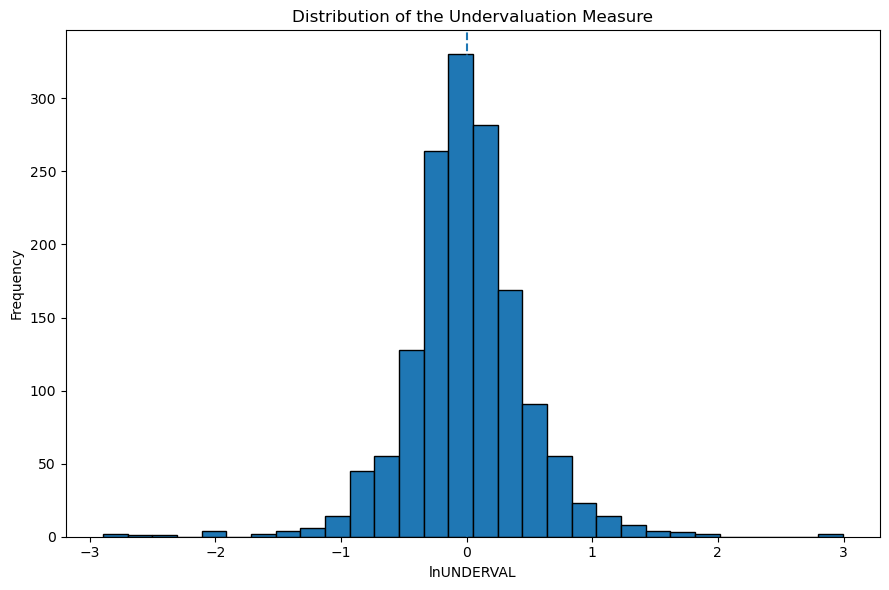

In [7]:
# ------------------------------------------------------------
# 14. FIGURE 2 — DISTRIBUTION OF UNDERVALUATION
# ------------------------------------------------------------

# Histogram of the undervaluation index, with a dashed vertical
# line at zero (a perfectly "aligned" exchange rate)
plt.figure(figsize=(9, 6))
plt.hist(
    pwt62["lnUNDERVAL_it"].dropna(),
    bins=30,
    edgecolor="black"
)
plt.axvline(
    0,
    linestyle="--"
)
plt.title(
    "Distribution of the Undervaluation Measure"
)
plt.xlabel(
    "lnUNDERVAL"
)
plt.ylabel(
    "Frequency"
)
plt.tight_layout()
plt.show()

In [8]:
# ------------------------------------------------------------
# 15. REMOVE OBSERVATIONS WITHOUT INITIAL INCOME
#     AND EXCLUDE IRAQ, LAOS AND NORTH KOREA
# ------------------------------------------------------------

# Keep only observations with initial income available (needed
# for growth) and drop the three countries Rodrik excludes for
# having extreme undervaluation values
pwt62 = pwt62[
    pwt62["lnRGDPCH_it_1"].notna()
    & ~pwt62["country"].isin(
        [
            "Iraq",
            "Laos",
            "Korea, Dem. Rep."
        ]
    )
].copy()

# ------------------------------------------------------------
# 16. SUBSAMPLES
# ------------------------------------------------------------

# Full sample (columns 1 and 4)
m_todos = pwt62.copy()

# Developed countries (column 2)
m_dev = pwt62[
    pwt62["developed"] == 1
].copy()

# Developing countries (column 3)
m_devp = pwt62[
    pwt62["developed"] == 0
].copy()

# Developing countries, before 1980 (column 5)
m_pre80 = pwt62[
    (pwt62["developed"] == 0)
    & (pwt62["period"] < 1980)
].copy()

# Developing countries, 1980 onwards (column 6)
m_post80 = pwt62[
    (pwt62["developed"] == 0)
    & (pwt62["period"] >= 1980)
].copy()

# ------------------------------------------------------------
# 17. FIXED-EFFECT REGRESSIONS
# ------------------------------------------------------------
# Every model includes country and period fixed effects
# (C(country), C(period)) and heteroskedasticity-robust
# standard errors (HC1).

# ------------------------------------------------------------
# COLUMN 1 — all countries
# ------------------------------------------------------------

col_1 = smf.ols(
    """
    growth_it ~
    lnRGDPCH_it_1 +
    lnUNDERVAL_it +
    C(country) +
    C(period)
    """,
    data=m_todos
).fit(
    cov_type="HC1"
)

# ------------------------------------------------------------
# COLUMN 2 — developed countries
# ------------------------------------------------------------

col_2 = smf.ols(
    """
    growth_it ~
    lnRGDPCH_it_1 +
    lnUNDERVAL_it +
    C(country) +
    C(period)
    """,
    data=m_dev
).fit(
    cov_type="HC1"
)

# ------------------------------------------------------------
# COLUMN 3 — developing countries
# ------------------------------------------------------------

col_3 = smf.ols(
    """
    growth_it ~
    lnRGDPCH_it_1 +
    lnUNDERVAL_it +
    C(country) +
    C(period)
    """,
    data=m_devp
).fit(
    cov_type="HC1"
)

# ------------------------------------------------------------
# COLUMN 4 — all countries, with interaction term
# ------------------------------------------------------------

# Adds initial income x undervaluation to test whether the
# growth effect of undervaluation varies with the income level
col_4 = smf.ols(
    """
    growth_it ~
    lnRGDPCH_it_1 +
    lnUNDERVAL_it +
    lnRGDPCH_it_1:lnUNDERVAL_it +
    C(country) +
    C(period)
    """,
    data=m_todos
).fit(
    cov_type="HC1"
)

# ------------------------------------------------------------
# COLUMN 5 — developing countries, pre-1980
# ------------------------------------------------------------

col_5 = smf.ols(
    """
    growth_it ~
    lnRGDPCH_it_1 +
    lnUNDERVAL_it +
    C(country) +
    C(period)
    """,
    data=m_pre80
).fit(
    cov_type="HC1"
)

# ------------------------------------------------------------
# COLUMN 6 — developing countries, 1980 onwards
# ------------------------------------------------------------

col_6 = smf.ols(
    """
    growth_it ~
    lnRGDPCH_it_1 +
    lnUNDERVAL_it +
    C(country) +
    C(period)
    """,
    data=m_post80
).fit(
    cov_type="HC1"
)

# ------------------------------------------------------------
# 18. RESULTS — TABLE 1
# ------------------------------------------------------------

# Collect the fitted models in column order
models = [
    col_1,
    col_2,
    col_3,
    col_4,
    col_5,
    col_6
]

# ------------------------------------------------------------
# COLUMN NAMES — RODRIK (2008)
# ------------------------------------------------------------

# Column labels as they appear in the original paper
model_names = [
    "1-1",
    "1-2",
    "1-3",
    "1-4",
    "1-5",
    "1-6"
]

# ------------------------------------------------------------
# SIGNIFICANCE STARS
# ------------------------------------------------------------

def significance_stars(p_value):
    """Return the significance stars for a p-value:
    *** p<0.01, ** p<0.05, * p<0.10, none otherwise."""

    if p_value < 0.01:
        return "***"

    elif p_value < 0.05:
        return "**"

    elif p_value < 0.10:
        return "*"

    else:
        return ""

# ------------------------------------------------------------
# FORMAT COEFFICIENT + T-STATISTIC
# ------------------------------------------------------------

def format_coefficient(model, variable):
    """Return the formatted coefficient (with stars) and the
    t-statistic (in parentheses) for a variable in a model.
    Returns empty strings if the variable is not in the model
    (e.g. the interaction term in columns other than 1-4)."""

    if variable not in model.params.index:
        return "", ""

    coefficient = model.params[variable]
    t_stat = model.tvalues[variable]
    p_value = model.pvalues[variable]

    stars = significance_stars(p_value)

    # Coefficient with three decimals plus stars
    coefficient_text = (
        f"{coefficient:.3f}{stars}"
    )

    # Robust t-statistic with two decimals, in parentheses
    t_stat_text = (
        f"({t_stat:.2f})"
    )

    return coefficient_text, t_stat_text

# ------------------------------------------------------------
# VARIABLES SHOWN IN TABLE
# ------------------------------------------------------------

# Only the coefficients of interest are reported; the fixed
# effects are omitted, as in the original table
variables = [
    "lnRGDPCH_it_1",
    "lnUNDERVAL_it",
    "lnRGDPCH_it_1:lnUNDERVAL_it"
]

# Readable labels for the table rows
variable_labels = {
    "lnRGDPCH_it_1":
        "Initial income",

    "lnUNDERVAL_it":
        "Undervaluation",

    "lnRGDPCH_it_1:lnUNDERVAL_it":
        "Initial income × Undervaluation"
}

# ------------------------------------------------------------
# BUILD TABLE
# ------------------------------------------------------------

# Dictionary-based draft of the table (the final table is built
# from the "rows" list below)
table = {}


for variable in variables:

    coefficient_row = []
    tstat_row = []

    for model in models:

        coefficient, tstat = format_coefficient(
            model,
            variable
        )

        coefficient_row.append(coefficient)
        tstat_row.append(tstat)

    table[
        variable_labels[variable]
    ] = coefficient_row

    table[
        " "  # temporary placeholder
    ] = tstat_row

# ------------------------------------------------------------
# CREATE OUTPUT ROWS
# ------------------------------------------------------------

# Build the table row by row: for each variable, one row with
# the coefficients and one row below it with the t-statistics
rows = []

for variable in variables:

    coefficient_row = []
    tstat_row = []

    for model in models:

        coefficient, tstat = format_coefficient(
            model,
            variable
        )

        coefficient_row.append(coefficient)
        tstat_row.append(tstat)

    # Coefficient row (labeled with the variable name)
    rows.append(
        [
            variable_labels[variable]
        ] + coefficient_row
    )

    # t-statistic row (blank label)
    rows.append(
        [
            ""
        ] + tstat_row
    )

# ------------------------------------------------------------
# ADD OBSERVATIONS AND R-SQUARED
# ------------------------------------------------------------

# Number of observations used in each regression
rows.append(
    [
        "Observations"
    ]
    +
    [
        f"{int(model.nobs)}"
        for model in models
    ]
)

# ------------------------------------------------------------
# FINAL TABLE
# ------------------------------------------------------------

# First column holds the row labels, followed by the six models
columns = [
    " ",
    *model_names
]

results_table = pd.DataFrame(
    rows,
    columns=columns
)

# ------------------------------------------------------------
# DISPLAY TABLE
# ------------------------------------------------------------

print("\n")
print("=" * 120)
print("TABLE 1 — RODRIK (2008)")
print("=" * 120)

print(
    results_table.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# TABLE NOTES
# ------------------------------------------------------------

# Column descriptions and notes, following the original paper
print("\n")

print(
    "Columns:",
    "1-1: All countries, 1950–2004",
    "1-2: Developed, 1950–2004",
    "1-3: Developing, 1950–2004",
    "1-4: All countries, 1950–2004",
    "1-5: Developing, 1950–1979",
    "1-6: Developing, 1980–2004",
    sep="\n"
)

print(
    "Notes:"
)

print(
    "a. The dependent variable is annual growth in GDP per capita, "
    "in percent. Observations are five-year averages. All regressions "
    "include time and country fixed effects."
)

print(
    "Countries with extreme observations for UNDERVAL "
    "(Iraq, Laos, and North Korea) have been excluded from the samples."
)

print(
    "Robust t statistics are in parentheses. Asterisks indicate "
    "statistical significance at the *10 percent, **5 percent, "
    "or ***1 percent level."
)

print(
    "b. Developed country observations are those with real GDP per capita "
    "exceeding $6,000."
)




TABLE 1 — RODRIK (2008)
                                      1-1       1-2       1-3       1-4       1-5       1-6
                 Initial income -0.030*** -0.054*** -0.039*** -0.032*** -0.063*** -0.065***
                                  (-6.72)   (-7.29)   (-5.59)   (-7.15)   (-3.87)   (-5.09)
                 Undervaluation  0.017***     0.004  0.027***  0.089***  0.031***  0.024***
                                   (5.10)    (0.59)    (5.76)    (4.12)    (4.07)    (3.15)
Initial income × Undervaluation                               -0.009***                    
                                                                (-3.46)                    
                   Observations      1303       513       790      1303       321       469


Columns:
1-1: All countries, 1950–2004
1-2: Developed, 1950–2004
1-3: Developing, 1950–2004
1-4: All countries, 1950–2004
1-5: Developing, 1950–1979
1-6: Developing, 1980–2004
Notes:
a. The dependent variable is annual growth in GDP per